# Cardiac Biomarker Evaluation

Loads trained biomarker artifacts produced by `cardiac_biomarker_training.ipynb` and reports validation/test-style out-of-fold ROC-AUC, PR-AUC, and SHAP/feature importance outputs.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    recall_score, precision_score, accuracy_score,
    matthews_corrcoef, roc_curve, precision_recall_curve
)

# Optional high-performance GBDT & XAI libraries
HAS_XGB = HAS_LGBM = HAS_CAT = HAS_SMOTE = HAS_SHAP = False

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    print("[Info] xgboost not installed. Install via: pip install xgboost")

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    print("[Info] lightgbm not installed. Install via: pip install lightgbm")

try:
    from catboost import CatBoostClassifier
    HAS_CAT = True
except ImportError:
    print("[Info] catboost not installed. Install via: pip install catboost")

try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
    HAS_SMOTE = True
except ImportError:
    print("[Info] imbalanced-learn not installed. Using class_weight balancing.")

try:
    import shap
    HAS_SHAP = True
except ImportError:
    print("[Info] shap not installed. Install via: pip install shap")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
print(f"Loaded | XGBoost: {HAS_XGB} | LightGBM: {HAS_LGBM} | CatBoost: {HAS_CAT} | SMOTE: {HAS_SMOTE} | SHAP: {HAS_SHAP}")


Loaded | XGBoost: True | LightGBM: True | CatBoost: True | SMOTE: True | SHAP: True


In [2]:
from pathlib import Path
current = Path.cwd()
PROJECT_ROOT = None
for candidate in [current] + list(current.parents):
    if (candidate / "src").is_dir():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the ml-service project root.")
OUTPUT_DIR = PROJECT_ROOT / "artifacts" / "metrics" / "biomarkers" / "cardiac_biomarker_pipeline"
SUMMARY_PATH = OUTPUT_DIR / "all_4_datasets_benchmark.csv"
print("Benchmark:", SUMMARY_PATH)


Benchmark: D:\Piyush\Cardio Project\CardioFusion-XAI\ml-service\artifacts\metrics\biomarkers\cardiac_biomarker_pipeline\all_4_datasets_benchmark.csv


In [3]:
# ==============================================================================
# 2. DATASET LOADERS & CLINICAL BIOMARKER FEATURE ENGINEERING
# ==============================================================================

def _normalize_cols(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [c.strip().lower().replace(" ", "_").replace("-", "_") for c in df.columns]
    return df


def load_and_engineer_zheen(path: str):
    """
    Zheen Hospital Heart Attack Dataset (1,319 records).
    Core Biomarkers: Troponin, CK-MB, Blood Sugar + Hemodynamics.
    """
    df = _normalize_cols(pd.read_csv(path))

    target_col = "result" if "result" in df.columns else df.columns[-1]
    if df[target_col].dtype == object:
        y = df[target_col].astype(str).str.strip().str.lower().map({"positive": 1, "negative": 0, "1": 1, "0": 0})
    else:
        y = df[target_col].astype(int)

    X = df.drop(columns=[target_col]).copy()

    hr_col = next((c for c in X.columns if "heart" in c or c == "impluse"), None)
    sbp_col = next((c for c in X.columns if "systolic" in c or "pressurehight" in c), None)
    dbp_col = next((c for c in X.columns if "diastolic" in c or "pressurelow" in c), None)
    sugar_col = next((c for c in X.columns if "sugar" in c or "glucose" in c), None)
    ckmb_col = next((c for c in X.columns if "ck" in c or "kcm" in c), None)
    trop_col = next((c for c in X.columns if "troponin" in c), None)

    # Clean known extreme outlier in Zheen heart_rate (e.g., 1111 bpm)
    if hr_col:
        X[hr_col] = X[hr_col].clip(lower=30, upper=240)

    # Biomarker & Hemodynamic Feature Engineering
    if sbp_col and dbp_col:
        X["pulse_pressure"] = X[sbp_col] - X[dbp_col]
        X["mean_arterial_pressure"] = X[dbp_col] + (X["pulse_pressure"] / 3.0)
    if hr_col and sbp_col:
        X["shock_index"] = X[hr_col] / (X[sbp_col].replace(0, np.nan))
    if trop_col:
        X["log_troponin"] = np.log1p(X[trop_col].clip(lower=0))
        X["troponin_elevated_flag"] = (X[trop_col] > 0.04).astype(int)
    if ckmb_col:
        X["log_ckmb"] = np.log1p(X[ckmb_col].clip(lower=0))
        X["ckmb_elevated_flag"] = (X[ckmb_col] > 25.0).astype(int)
    if trop_col and ckmb_col:
        X["myocardial_injury_index"] = X["log_troponin"] * X["log_ckmb"]
    if sugar_col:
        X["hyperglycemia_flag"] = (X[sugar_col] > 140).astype(int)

    biomarkers = [c for c in [trop_col, ckmb_col, sugar_col, "log_troponin", "log_ckmb", "myocardial_injury_index"] if c in X.columns]
    return X, y.astype(int), biomarkers


def load_and_engineer_uci_hf(path: str, include_time: bool = False):
    """
    UCI Heart Failure Clinical Records (299 records).
    Core Biomarkers: Serum Creatinine, Ejection Fraction, CPK, Serum Sodium, Platelets.
    """
    df = _normalize_cols(pd.read_csv(path))
    target_col = "death_event" if "death_event" in df.columns else df.columns[-1]
    y = df[target_col].astype(int)
    X = df.drop(columns=[target_col]).copy()

    if not include_time and "time" in X.columns:
        X = X.drop(columns=["time"])

    # Biomarker Feature Engineering (Chicco & Jurman 2020 inspired)
    if "creatinine_phosphokinase" in X.columns:
        X["log_cpk"] = np.log1p(X["creatinine_phosphokinase"].clip(lower=0))
    if "serum_creatinine" in X.columns and "ejection_fraction" in X.columns:
        X["creatinine_to_ef_ratio"] = X["serum_creatinine"] / (X["ejection_fraction"] + 1e-5)
        X["cardiorenal_risk_flag"] = ((X["serum_creatinine"] > 1.5) & (X["ejection_fraction"] < 40)).astype(int)
    if "serum_sodium" in X.columns and "serum_creatinine" in X.columns:
        X["sodium_to_creatinine_ratio"] = X["serum_sodium"] / (X["serum_creatinine"] + 1e-5)
        X["hyponatremia_flag"] = (X["serum_sodium"] < 135).astype(int)
    if "platelets" in X.columns:
        X["log_platelets"] = np.log1p(X["platelets"].clip(lower=0))

    biomarkers = [c for c in [
        "serum_creatinine", "ejection_fraction", "creatinine_phosphokinase",
        "serum_sodium", "platelets", "creatinine_to_ef_ratio", "sodium_to_creatinine_ratio"
    ] if c in X.columns]
    return X, y, biomarkers


def load_and_engineer_framingham(path: str):
    """
    Framingham Heart Study Dataset (~4,240 records).
    Core Biomarkers: Total Cholesterol, Glucose, Systolic/Diastolic BP, BMI, Heart Rate.
    """
    df = _normalize_cols(pd.read_csv(path))
    target_col = "tenyearchd" if "tenyearchd" in df.columns else df.columns[-1]
    y = df[target_col].astype(int)
    X = df.drop(columns=[target_col]).copy()

    if "education" in X.columns:
        X = X.drop(columns=["education"])

    # Biomarker Feature Engineering
    if "sysbp" in X.columns and "diabp" in X.columns:
        X["pulse_pressure"] = X["sysbp"] - X["diabp"]
        X["mean_arterial_pressure"] = X["diabp"] + (X["pulse_pressure"] / 3.0)
        X["hypertension_stage2_flag"] = ((X["sysbp"] >= 140) | (X["diabp"] >= 90)).astype(int)
    if "glucose" in X.columns:
        X["log_glucose"] = np.log1p(X["glucose"].clip(lower=0))
        X["impaired_glucose_flag"] = (X["glucose"] >= 126).astype(int)
    if "totchol" in X.columns and "bmi" in X.columns:
        X["chol_bmi_product"] = X["totchol"] * X["bmi"]
    if "age" in X.columns and "sysbp" in X.columns:
        X["age_x_sysbp"] = X["age"] * X["sysbp"]

    biomarkers = [c for c in [
        "totchol", "glucose", "sysbp", "diabp", "bmi", "heartrate",
        "pulse_pressure", "mean_arterial_pressure", "log_glucose"
    ] if c in X.columns]
    return X, y, biomarkers


def load_and_engineer_mi_complications(path: str, target_col: str = "LET_IS"):
    """
    UCI Myocardial Infarction Complications Dataset (1,700 records, 124 columns).
    Core Blood Biomarkers: K_BLOOD, NA_BLOOD, ALT_BLOOD, AST_BLOOD, L_BLOOD (WBC), ROE (ESR).
    """
    df = pd.read_csv(path, na_values=["?", "NA", "nan", ""])
    df = _normalize_cols(df)

    for id_col in ["id", "unnamed:_0"]:
        if id_col in df.columns:
            df = df.drop(columns=[id_col])

    known_outcomes = [
        "fibr_preds", "preds_tah", "jelud_tah", "fibr_jelud", "a_v_blok",
        "otek_lanc", "razriv", "dressler", "zsn", "rec_im", "p_im_sten", "let_is"
    ]
    t_col = target_col.strip().lower()
    if t_col not in df.columns:
        t_col = df.columns[-1]

    y = (pd.to_numeric(df[t_col], errors="coerce").fillna(0) > 0).astype(int)

    # Drop ALL 12 outcome columns from X to prevent target leakage
    outcome_cols_present = [c for c in known_outcomes if c in df.columns]
    if t_col not in outcome_cols_present:
        outcome_cols_present.append(t_col)
    X = df.drop(columns=outcome_cols_present).copy()

    X = X.apply(pd.to_numeric, errors="coerce")

    # Drop columns with >50% missing values (e.g., kfk_blood is >99% missing in UCI MI)
    missing_frac = X.isna().mean()
    X = X.loc[:, missing_frac <= 0.50].copy()

    # Clinical Blood Biomarker Engineering
    if "ast_blood" in X.columns and "alt_blood" in X.columns:
        X["ast_alt_ratio"] = X["ast_blood"] / (X["alt_blood"].replace(0, np.nan) + 1e-5)
    if "na_blood" in X.columns and "k_blood" in X.columns:
        X["na_k_ratio"] = X["na_blood"] / (X["k_blood"].replace(0, np.nan) + 1e-5)
        X["hypokalemia_flag"] = (X["k_blood"] < 3.5).astype(int)
    if "s_ad_orit" in X.columns and "d_ad_orit" in X.columns:
        X["icu_pulse_pressure"] = X["s_ad_orit"] - X["d_ad_orit"]
    if "l_blood" in X.columns:
        X["log_wbc"] = np.log1p(X["l_blood"].clip(lower=0))

    biomarkers = [c for c in [
        "k_blood", "na_blood", "alt_blood", "ast_blood", "l_blood", "roe",
        "ast_alt_ratio", "na_k_ratio", "icu_pulse_pressure", "log_wbc"
    ] if c in X.columns]
    return X, y, biomarkers


In [4]:
# ==============================================================================
# 4. ROC / PR CURVES & SHAP BIOMARKER EXPLAINABILITY
# ==============================================================================

def plot_roc_pr_curves(dataset_name: str, y: pd.Series, oof_probas: dict):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    for model_name, proba in oof_probas.items():
        fpr, tpr, _ = roc_curve(y, proba)
        auc_val = roc_auc_score(y, proba)
        axes[0].plot(fpr, tpr, label=f"{model_name} (AUC={auc_val:.3f})", lw=2)

        prec, rec, _ = precision_recall_curve(y, proba)
        ap_val = average_precision_score(y, proba)
        axes[1].plot(rec, prec, label=f"{model_name} (AP={ap_val:.3f})", lw=2)

    axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[0].set_title(f"{dataset_name} — ROC Curve")
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate (Recall)")
    axes[0].legend(loc="lower right", fontsize=8)

    axes[1].set_title(f"{dataset_name} — Precision-Recall Curve")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].legend(loc="lower left", fontsize=8)

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{dataset_name}_roc_pr.png"), dpi=150)
    plt.show()


def explain_biomarkers_shap(dataset_name: str, shap_model_name: str, shap_pipe, X: pd.DataFrame):
    """Computes and plots top biomarker feature importances using TreeSHAP."""
    imputer = shap_pipe.named_steps["imputer"]
    clf = shap_pipe.named_steps["clf"]
    X_imp = pd.DataFrame(imputer.transform(X), columns=X.columns)

    if HAS_SHAP and shap_model_name in ["XGBoost", "LightGBM", "CatBoost", "RandomForest"]:
        explainer = shap.TreeExplainer(clf)
        shap_vals = explainer.shap_values(X_imp)

        if isinstance(shap_vals, list):
            shap_vals = shap_vals[1]
        elif shap_vals.ndim == 3:
            shap_vals = shap_vals[:, :, 1]

        plt.figure(figsize=(9, 5))
        shap.summary_plot(shap_vals, X_imp, max_display=12, show=False)
        plt.title(f"{dataset_name} — Top Biomarker Impact (SHAP | {shap_model_name})")
        plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_DIR, f"{dataset_name}_shap_biomarkers.png"), dpi=150, bbox_inches="tight")
        plt.show()

        imp_df = pd.DataFrame({
            "Feature": X.columns,
            "Mean_Abs_SHAP": np.abs(shap_vals).mean(axis=0)
        }).sort_values("Mean_Abs_SHAP", ascending=False).head(10)
        return imp_df
    else:
        if hasattr(clf, "feature_importances_"):
            imp_df = pd.DataFrame({
                "Feature": X.columns,
                "Importance": clf.feature_importances_
            }).sort_values("Importance", ascending=False).head(10)
            plt.figure(figsize=(8, 4))
            sns.barplot(data=imp_df, x="Importance", y="Feature", palette="viridis")
            plt.title(f"{dataset_name} — Top Biomarkers ({shap_model_name})")
            plt.tight_layout()
            plt.show()
            return imp_df
        return pd.DataFrame()


Saved benchmark:


,Dataset,Model,ROC_AUC,PR_AUC,F1,Recall,Precision,Accuracy,MCC
0,Framingham,LogisticRegression,0.721572,0.329034,0.384141,0.677019,0.268143,0.670283,0.255467
1,Framingham,RandomForest,0.703332,0.306958,0.320065,0.305901,0.335605,0.802594,0.205191
2,Framingham,XGBoost,0.679470,0.301450,0.250000,0.187888,0.373457,0.828774,0.177572
3,Framingham,Stacked_GBDT_Ensemble,0.676085,0.294932,0.299357,0.253106,0.366292,0.820047,0.204561
4,Framingham,CatBoost,0.669753,0.290242,0.229759,0.163043,0.388889,0.833962,0.172207
5,Framingham,HistGradientBoosting,0.669444,0.284669,0.245868,0.184783,0.367284,0.827830,0.172625
6,Framingham,LightGBM,0.668692,0.284646,0.243386,0.178571,0.382060,0.831368,0.177279
7,MI_Complications,CatBoost,0.882786,0.661918,0.544622,0.439114,0.716867,0.882941,0.500956
8,MI_Complications,HistGradientBoosting,0.881872,0.665529,0.552036,0.450185,0.713450,0.883529,0.506154
9,MI_Complications,LightGBM,0.881738,0.664005,0.533333,0.428044,0.707317,0.880588,0.489080



=== BEST MODEL PER DATASET ===


,Dataset,Model,ROC_AUC,PR_AUC,F1,Recall,Precision,MCC,Accuracy
0,Framingham,LogisticRegression,0.721572,0.329034,0.384141,0.677019,0.268143,0.255467,0.670283
1,MI_Complications,CatBoost,0.882786,0.661918,0.544622,0.439114,0.716867,0.500956,0.882941
2,UCI_Heart_Failure,RandomForest,0.784893,0.631318,0.653846,0.708333,0.607143,0.474190,0.759197
3,Zheen,RandomForest,0.997034,0.998086,0.988820,0.982716,0.995000,0.971435,0.986353


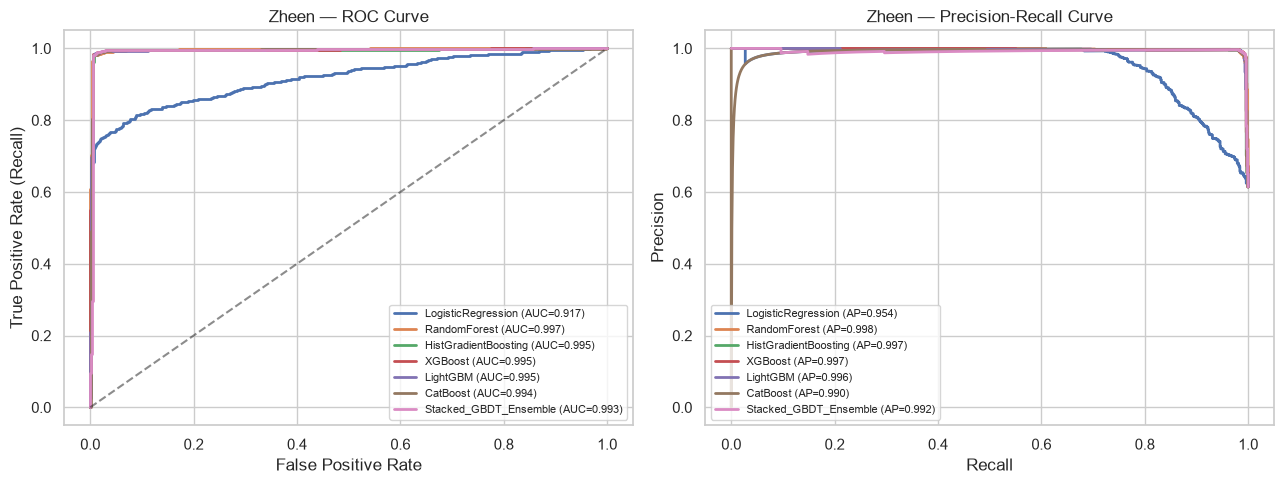

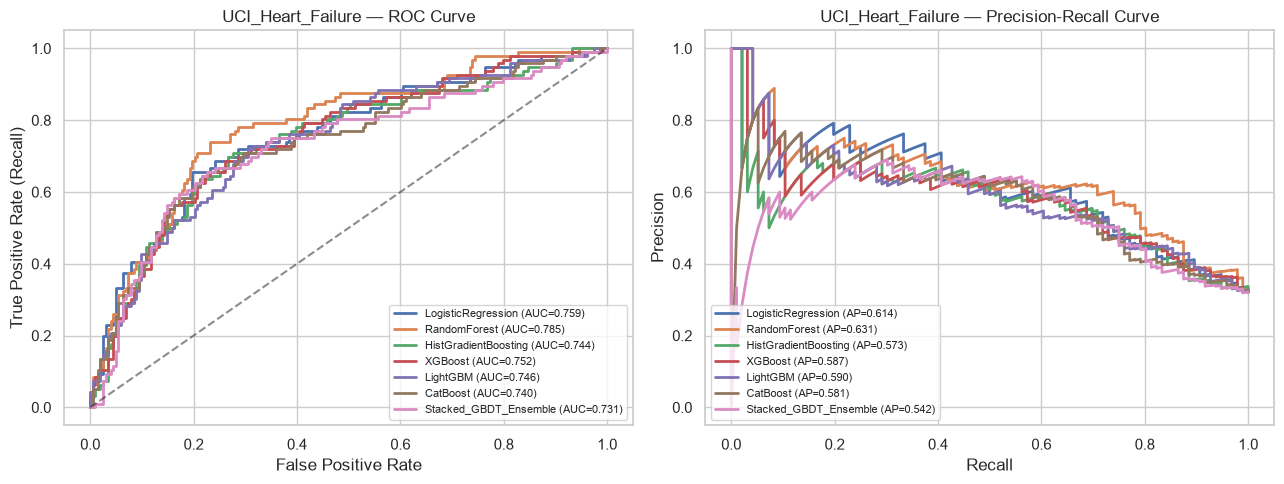

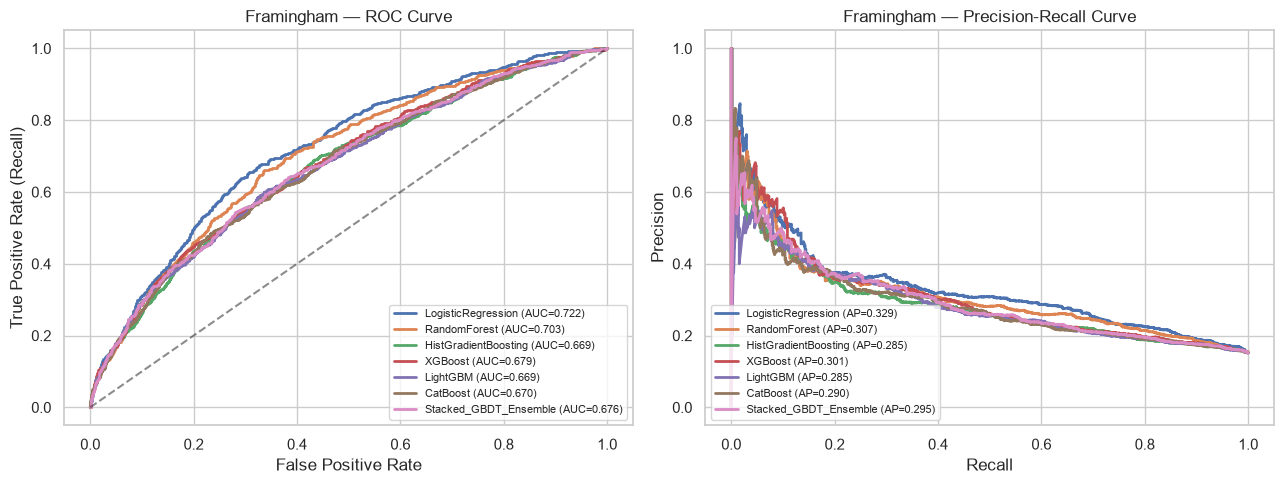

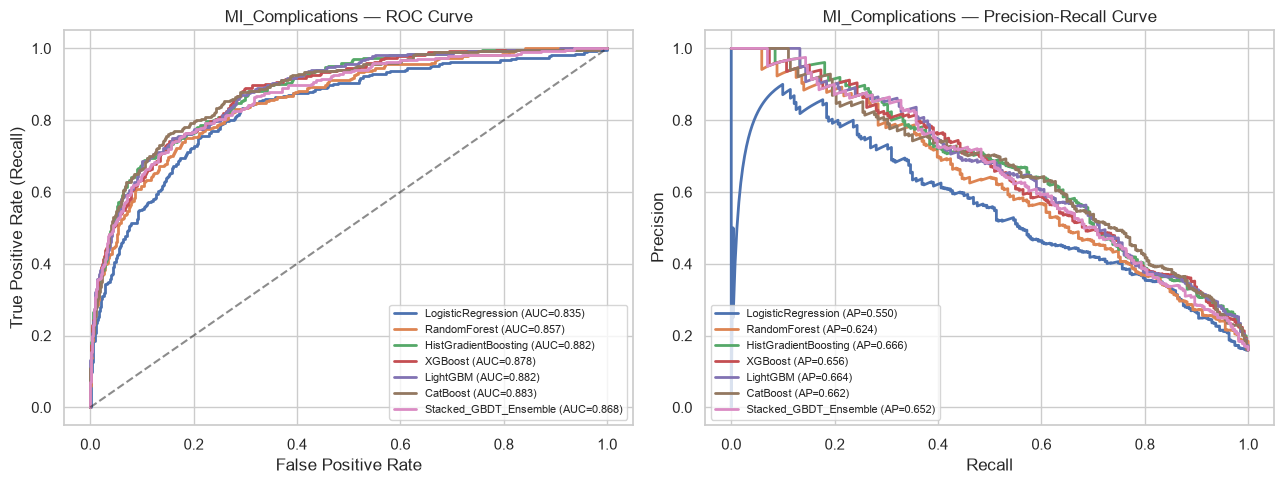

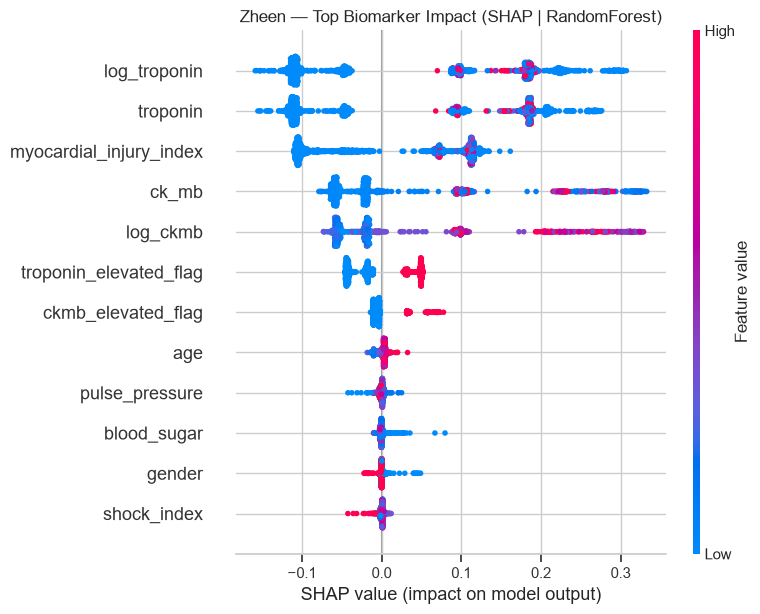


Zheen top biomarker/feature importance:


,Feature,Mean_Abs_SHAP
11,log_troponin,0.136267
7,troponin,0.133611
15,myocardial_injury_index,0.093889
6,ck_mb,0.072835
13,log_ckmb,0.069342
12,troponin_elevated_flag,0.036166
14,ckmb_elevated_flag,0.010566
0,age,0.004383
8,pulse_pressure,0.001886
5,blood_sugar,0.001876


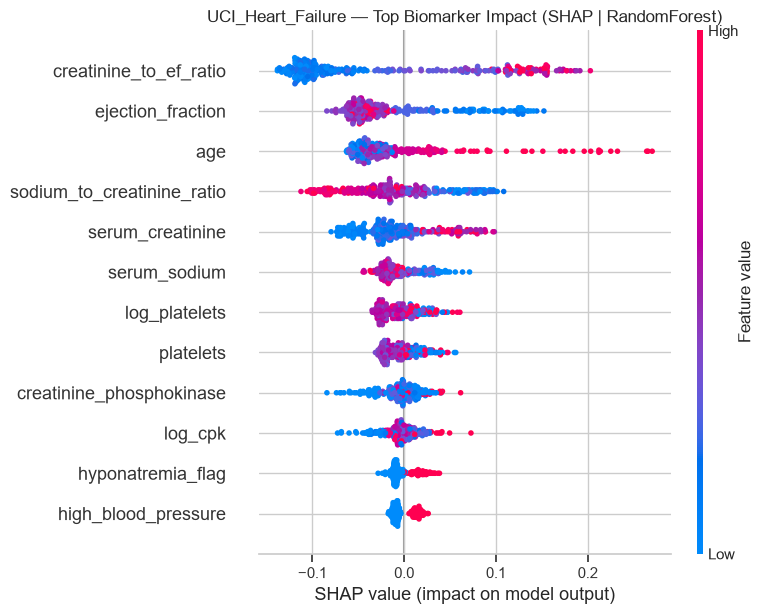


UCI_Heart_Failure top biomarker/feature importance:


,Feature,Mean_Abs_SHAP
12,creatinine_to_ef_ratio,0.099612
4,ejection_fraction,0.050392
0,age,0.044584
14,sodium_to_creatinine_ratio,0.042976
7,serum_creatinine,0.033840
8,serum_sodium,0.018550
16,log_platelets,0.016878
6,platelets,0.015169
2,creatinine_phosphokinase,0.014968
11,log_cpk,0.013325


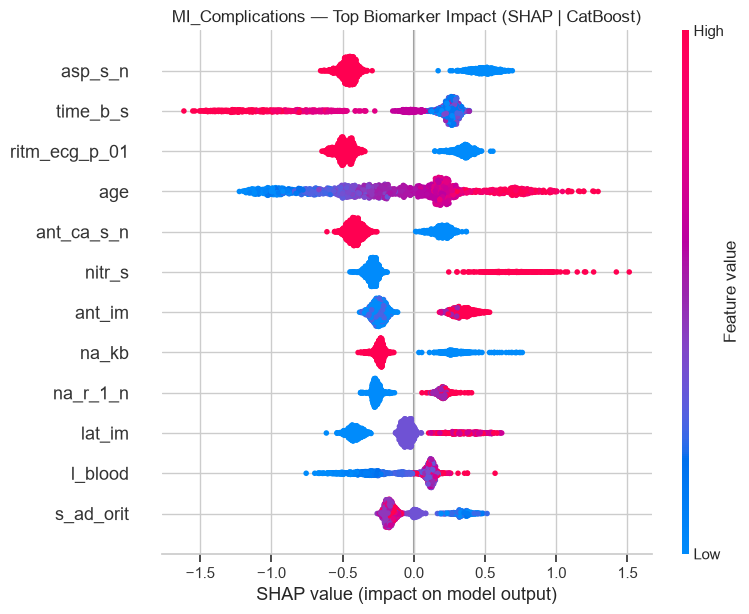


MI_Complications top biomarker/feature importance:


,Feature,Mean_Abs_SHAP
104,asp_s_n,0.465980
86,time_b_s,0.458516
45,ritm_ecg_p_01,0.445052
0,age,0.442072
102,ant_ca_s_n,0.343121
93,nitr_s,0.339305
40,ant_im,0.278386
90,na_kb,0.255963
94,na_r_1_n,0.242888
41,lat_im,0.212208


In [5]:
summary_df = pd.read_csv(SUMMARY_PATH)
print("Saved benchmark:")
display(summary_df.sort_values(["Dataset", "ROC_AUC"], ascending=[True, False]).reset_index(drop=True))

print("\n=== BEST MODEL PER DATASET ===")
best_per_ds = summary_df.sort_values("ROC_AUC", ascending=False).groupby("Dataset", as_index=False).first()
display(best_per_ds[["Dataset", "Model", "ROC_AUC", "PR_AUC", "F1", "Recall", "Precision", "MCC", "Accuracy"]])

for name in ["Zheen", "UCI_Heart_Failure", "Framingham", "MI_Complications"]:
    oof_path = OUTPUT_DIR / f"{name}_oof_predictions.csv"
    if not oof_path.exists():
        print(f"[Skipped] Missing OOF predictions: {oof_path}")
        continue
    oof_df = pd.read_csv(oof_path)
    oof_probas = {column: oof_df[column].to_numpy() for column in oof_df.columns if column != "true"}
    plot_roc_pr_curves(name, pd.Series(oof_df["true"]), oof_probas)

DATA_PATHS = {
    "Zheen": PROJECT_ROOT / "data" / "raw" / "biomarkers" / "zheen" / "Medicaldataset.csv",
    "UCI_Heart_Failure": PROJECT_ROOT / "data" / "raw" / "biomarkers" / "uci_heart_failure" / "Heart_failure_clinical_records_dataset.csv",
    "Framingham": PROJECT_ROOT / "data" / "raw" / "biomarkers" / "framingham" / "framingham.csv",
    "MI_Complications": PROJECT_ROOT / "data" / "raw" / "biomarkers" / "mi_complications" / "Myocardial infarction complications Database.csv",
}
LOADERS = {
    "Zheen": lambda p: load_and_engineer_zheen(p),
    "UCI_Heart_Failure": lambda p: load_and_engineer_uci_hf(p, include_time=False),
    "Framingham": lambda p: load_and_engineer_framingham(p),
    "MI_Complications": lambda p: load_and_engineer_mi_complications(p, target_col="LET_IS"),
}

for name, data_path in DATA_PATHS.items():
    model_path = OUTPUT_DIR / f"best_model_{name}.joblib"
    if not model_path.exists():
        print(f"[Skipped] Missing checkpoint: {model_path}")
        continue
    X, y, biomarkers = LOADERS[name](str(data_path))
    best_pipe = joblib.load(model_path)
    clf = best_pipe.named_steps["clf"]
    if isinstance(clf, RandomForestClassifier):
        model_name = "RandomForest"
    elif isinstance(clf, HistGradientBoostingClassifier):
        model_name = "HistGradientBoosting"
    elif HAS_CAT and isinstance(clf, CatBoostClassifier):
        model_name = "CatBoost"
    elif HAS_XGB and isinstance(clf, XGBClassifier):
        model_name = "XGBoost"
    elif HAS_LGBM and isinstance(clf, LGBMClassifier):
        model_name = "LightGBM"
    else:
        model_name = "LogisticRegression"
    imp_df = explain_biomarkers_shap(name, model_name, best_pipe, X)
    if not imp_df.empty:
        print(f"\n{name} top biomarker/feature importance:")
        display(imp_df)
